# Data Cleaning and Preprocessing for Social Media Addiction Detection

This notebook performs comprehensive data cleaning and preprocessing on the Social Media Addiction dataset to prepare it for machine learning-based clustering and early addiction detection. The objective is to ensure data consistency, numerical stability, and proper encoding, making the dataset suitable for distance-based unsupervised learning algorithms such as K-Means.

## Table of Contents
1. Import Required Libraries
2. Load and Explore Dataset
3. Missing and Null Value Handling
4. Weekly Usage Consistency Rules
5. Inconsistency and Outlier Removal
6. Categorical Feature Encoding
7. Feature Scaling / Normalization
8. Export Cleaned Dataset

## 1. Import Required Libraries

We begin by importing essential Python libraries for data manipulation, analysis, and preprocessing:
- **pandas**: For data loading and manipulation
- **numpy**: For numerical operations
- **scikit-learn**: For preprocessing tools (encoding, scaling, outlier detection)

In [1]:
# Import Required Libraries
import pandas as pd
import numpy as np
import warnings
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load and Explore Dataset

Load the Social Media Addiction dataset and perform initial exploratory analysis to understand:
- Dataset dimensions (rows and columns)
- Data types of features
- Presence of missing values
- Basic statistical summaries

In [2]:
# Load the dataset
df = pd.read_csv('../Social_Media_Addiction.csv')

# Display basic information
print("="*70)
print("DATASET OVERVIEW")
print("="*70)
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")

# Display first few rows
print("First 5 rows of the dataset:")
print(df.head())

# Display data types
print("\n" + "="*70)
print("DATA TYPES")
print("="*70)
print(df.dtypes)

DATASET OVERVIEW
Dataset Shape: 691 rows × 27 columns

First 5 rows of the dataset:
   Gender  What is your age? What is your current occupation? Facebook Week 1  \
0    Male                 35                         Employed            7:44   
1  Female                 19                          Student            0:51   
2    Male                 23                          Student            0:13   
3    Male                 21                          Student           24:17   
4  Female                 19                          Student            5:26   

  Facebook Week 2 Facebook Week 3 Facebook Week 4 Messenger Week 1  \
0            7:43            9:28            5:54             5:23   
1            0:52            1:14            0:59             0:51   
2            0:24            0:44            0:01             0:02   
3           21:22           25:38           23:11             4:09   
4            4:37            6:07            5:05             4:34   

  Messen

In [3]:
df.head(10)

,Gender,What is your age?,What is your current occupation?,Facebook Week 1,Facebook Week 2,Facebook Week 3,Facebook Week 4,Messenger Week 1,Messenger Week 2,Messenger Week 3,...,Instagram Week 3,Instagram Week 4,YouTube Week 1,YouTube Week 2,YouTube Week 3,YouTube Week 4,TikTok Week 1,TikTok Week 2,TikTok Week 3,TikTok Week 4
0,Male,35,Employed,7:44,7:43,9:28,5:54,5:23,4:43,4:43,...,8:26,7:49,2:41,0:44,1:00,3:02,0:00,0:00,0:00,0:00
1,Female,19,Student,0:51,0:52,1:14,0:59,0:51,0:53,0:55,...,0:24,0:25,0:13,0:15,0:17,0:18,0,0,0,0
2,Male,23,Student,0:13,0:24,0:44,0:01,0:02,0:10,0:01,...,0,0,30,1:14,0:01,0:01,0,0,0,0
3,Male,21,Student,24:17,21:22,25:38,23:11,4:09,4:38,3:40,...,1:56,1:23,3:09,3:20,2:34,4:09,0,0,0,0
4,Female,19,Student,5:26,4:37,6:07,5:05,4:34,3:42,3:23,...,3:23,4:43,4:00,5:18,4:27,4:47,0,0,0,0
5,Female,23,Student,1:31,1:30,1:30,1:31,0:17,0:23,0:17,...,4:06,3:57,4:09,4:04,3:46,5:02,0,0,0,0
6,Female,25,Student,0:14,0:12,0:12,0:15,1:57,1:44,2:02,...,1:18,1:11,2:22,1:59,1:56,1:38,2:55,3:04,2:33,2:11
7,Male,24,Student,11:27,9:34,12:35,10:41,10:55,9:00,10:13,...,20:59,21:03,37:33,35:35,39:08,36:30,0:00,0:00,0:00,0:00
8,Male,43,Employed,5:07,4:06,4:25,4:16,4:01,3:58,3:42,...,7:51,8:19,5:44,7:11,4:18,4:10,0:00,0:00,0:00,0:00
9,Male,24,Student,14:23,12:34,15:35,16:37,0:50,0:23,0:23,...,0,0,16:20,23:40,25:15,19:23,0,0,0,0


### Check for Missing Values

Identify the presence and distribution of missing or null values across all features in the dataset.

In [4]:
# Check for missing values
print("="*70)
print("MISSING VALUES ANALYSIS")
print("="*70)

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Column': missing_values.index,
    'Missing Count': missing_values.values,
    'Percentage': missing_percentage.values
})

missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

if len(missing_df) > 0:
    print(missing_df.to_string(index=False))
else:
    print("No missing values detected in the dataset!")

print(f"\nTotal Missing Values: {df.isnull().sum().sum()}")

MISSING VALUES ANALYSIS
No missing values detected in the dataset!

Total Missing Values: 0


In [5]:
df.head()

,Gender,What is your age?,What is your current occupation?,Facebook Week 1,Facebook Week 2,Facebook Week 3,Facebook Week 4,Messenger Week 1,Messenger Week 2,Messenger Week 3,...,Instagram Week 3,Instagram Week 4,YouTube Week 1,YouTube Week 2,YouTube Week 3,YouTube Week 4,TikTok Week 1,TikTok Week 2,TikTok Week 3,TikTok Week 4
0,Male,35,Employed,7:44,7:43,9:28,5:54,5:23,4:43,4:43,...,8:26,7:49,2:41,0:44,1:00,3:02,0:00,0:00,0:00,0:00
1,Female,19,Student,0:51,0:52,1:14,0:59,0:51,0:53,0:55,...,0:24,0:25,0:13,0:15,0:17,0:18,0,0,0,0
2,Male,23,Student,0:13,0:24,0:44,0:01,0:02,0:10,0:01,...,0,0,30,1:14,0:01,0:01,0,0,0,0
3,Male,21,Student,24:17,21:22,25:38,23:11,4:09,4:38,3:40,...,1:56,1:23,3:09,3:20,2:34,4:09,0,0,0,0
4,Female,19,Student,5:26,4:37,6:07,5:05,4:34,3:42,3:23,...,3:23,4:43,4:00,5:18,4:27,4:47,0,0,0,0


In [6]:
# Function to convert time string to minutes
def time_to_minutes(time_str):
    """
    Convert time string in format HH:MM or MM:SS or just numbers to total minutes.
    Handles various formats and inconsistencies in the data.
    """
    if pd.isna(time_str):
        return 0
    
    time_str = str(time_str).strip()
    
    # Handle empty strings or '0'
    if time_str == '' or time_str == '0':
        return 0
    
    # Handle pure numbers (assume they are minutes)
    try:
        if ':' not in time_str:
            return float(time_str)
    except:
        return 0
    
    # Handle time format HH:MM or MM:SS
    try:
        parts = time_str.split(':')
        if len(parts) == 2:
            hours_or_mins = float(parts[0])
            mins_or_secs = float(parts[1])
            # Convert to total minutes (treating as HH:MM format)
            return hours_or_mins * 60 + mins_or_secs
        return 0
    except:
        return 0

# Get all usage columns (all columns except Gender, Age, and Occupation)
usage_columns = [col for col in df.columns if 'Week' in col]

print("="*70)
print("CONVERTING TIME FORMAT TO MINUTES")
print("="*70)
print(f"Converting {len(usage_columns)} usage columns to numerical format (minutes)...\n")

# Apply conversion to all usage columns
for col in usage_columns:
    df[col] = df[col].apply(time_to_minutes)

print("✓ Conversion completed successfully!")
print("\nSample of converted data:")
print(df[usage_columns[:6]].head())

CONVERTING TIME FORMAT TO MINUTES
Converting 24 usage columns to numerical format (minutes)...

✓ Conversion completed successfully!

Sample of converted data:
   Facebook Week 1  Facebook Week 2  Facebook Week 3  Facebook Week 4  \
0            464.0            463.0            568.0            354.0   
1             51.0             52.0             74.0             59.0   
2             13.0             24.0             44.0              1.0   
3           1457.0           1282.0           1538.0           1391.0   
4            326.0            277.0            367.0            305.0   

   Messenger Week 1  Messenger Week 2  
0             323.0             283.0  
1              51.0              53.0  
2               2.0              10.0  
3             249.0             278.0  
4             274.0             222.0  


In [7]:
df.head()

,Gender,What is your age?,What is your current occupation?,Facebook Week 1,Facebook Week 2,Facebook Week 3,Facebook Week 4,Messenger Week 1,Messenger Week 2,Messenger Week 3,...,Instagram Week 3,Instagram Week 4,YouTube Week 1,YouTube Week 2,YouTube Week 3,YouTube Week 4,TikTok Week 1,TikTok Week 2,TikTok Week 3,TikTok Week 4
0,Male,35,Employed,464.0,463.0,568.0,354.0,323.0,283.0,283.0,...,506.0,469.0,161.0,44.0,60.0,182.0,0.0,0.0,0.0,0.0
1,Female,19,Student,51.0,52.0,74.0,59.0,51.0,53.0,55.0,...,24.0,25.0,13.0,15.0,17.0,18.0,0.0,0.0,0.0,0.0
2,Male,23,Student,13.0,24.0,44.0,1.0,2.0,10.0,1.0,...,0.0,0.0,30.0,74.0,1.0,1.0,0.0,0.0,0.0,0.0
3,Male,21,Student,1457.0,1282.0,1538.0,1391.0,249.0,278.0,220.0,...,116.0,83.0,189.0,200.0,154.0,249.0,0.0,0.0,0.0,0.0
4,Female,19,Student,326.0,277.0,367.0,305.0,274.0,222.0,203.0,...,203.0,283.0,240.0,318.0,267.0,287.0,0.0,0.0,0.0,0.0


## 3. Missing and Null Value Handling

After converting time formats to numerical values, we handle any remaining missing or null values using appropriate strategies:

**Strategy:**
- **Numerical features (usage data)**: Replace missing values with 0, as missing usage indicates no activity
- **Categorical features**: Replace with mode (most frequent value) if any missing values exist

This approach maintains data integrity while ensuring no information loss for machine learning algorithms.

In [8]:
# Handle missing values
print("="*70)
print("HANDLING MISSING VALUES")
print("="*70)

# Identify categorical and numerical columns
categorical_cols = ['Gender', 'What is your current occupation?']
numerical_cols = ['What is your age?'] + usage_columns

# Handle numerical features - replace with 0
for col in numerical_cols:
    missing_count = df[col].isnull().sum()
    if missing_count > 0:
        df[col].fillna(0, inplace=True)
        print(f"✓ {col}: Filled {missing_count} missing values with 0")

# Handle categorical features - replace with mode
for col in categorical_cols:
    missing_count = df[col].isnull().sum()
    if missing_count > 0:
        mode_value = df[col].mode()[0]
        df[col].fillna(mode_value, inplace=True)
        print(f"✓ {col}: Filled {missing_count} missing values with mode '{mode_value}'")

print(f"\nTotal missing values after handling: {df.isnull().sum().sum()}")
print("✓ All missing values handled successfully!")

HANDLING MISSING VALUES

Total missing values after handling: 0
✓ All missing values handled successfully!


In [9]:
df.shape

(691, 27)

### Calculate Monthly Totals per Platform

Before outlier detection, we calculate the total monthly usage for each platform by summing the four weekly usage values. This aggregation provides a comprehensive view of user behavior per platform.

In [10]:
# Calculate monthly totals for each platform
print("="*70)
print("CALCULATING MONTHLY TOTALS PER PLATFORM")
print("="*70)

platforms = ['Facebook', 'Instagram', 'Messenger', 'TikTok', 'WhatsApp', 'YouTube']

for platform in platforms:
    week_cols = [f'{platform} Week {i}' for i in range(1, 5)]
    monthly_col = f'{platform}_Monthly_Total'
    df[monthly_col] = df[week_cols].sum(axis=1)
    print(f"✓ {platform}: Monthly total calculated")

# Create list of monthly total columns
monthly_columns = [f'{platform}_Monthly_Total' for platform in platforms]

print(f"\n✓ Created {len(monthly_columns)} monthly total features")
print("\nSample of monthly totals:")
print(df[['Gender'] + monthly_columns[:3]].head())

CALCULATING MONTHLY TOTALS PER PLATFORM
✓ Facebook: Monthly total calculated
✓ Instagram: Monthly total calculated
✓ Messenger: Monthly total calculated
✓ TikTok: Monthly total calculated
✓ WhatsApp: Monthly total calculated
✓ YouTube: Monthly total calculated

✓ Created 6 monthly total features

Sample of monthly totals:
   Gender  Facebook_Monthly_Total  Instagram_Monthly_Total  \
0    Male                  1849.0                   1748.0   
1  Female                   236.0                     92.0   
2    Male                    82.0                      0.0   
3    Male                  5668.0                    351.0   
4  Female                  1275.0                   1046.0   

   Messenger_Monthly_Total  
0                   1186.0  
1                    210.0  
2                     52.0  
3                   1050.0  
4                    896.0  


In [11]:
df.head()

,Gender,What is your age?,What is your current occupation?,Facebook Week 1,Facebook Week 2,Facebook Week 3,Facebook Week 4,Messenger Week 1,Messenger Week 2,Messenger Week 3,...,TikTok Week 1,TikTok Week 2,TikTok Week 3,TikTok Week 4,Facebook_Monthly_Total,Instagram_Monthly_Total,Messenger_Monthly_Total,TikTok_Monthly_Total,WhatsApp_Monthly_Total,YouTube_Monthly_Total
0,Male,35,Employed,464.0,463.0,568.0,354.0,323.0,283.0,283.0,...,0.0,0.0,0.0,0.0,1849.0,1748.0,1186.0,0.0,1989.0,447.0
1,Female,19,Student,51.0,52.0,74.0,59.0,51.0,53.0,55.0,...,0.0,0.0,0.0,0.0,236.0,92.0,210.0,0.0,275.0,63.0
2,Male,23,Student,13.0,24.0,44.0,1.0,2.0,10.0,1.0,...,0.0,0.0,0.0,0.0,82.0,0.0,52.0,0.0,83.0,106.0
3,Male,21,Student,1457.0,1282.0,1538.0,1391.0,249.0,278.0,220.0,...,0.0,0.0,0.0,0.0,5668.0,351.0,1050.0,0.0,248.0,792.0
4,Female,19,Student,326.0,277.0,367.0,305.0,274.0,222.0,203.0,...,0.0,0.0,0.0,0.0,1275.0,1046.0,896.0,0.0,543.0,1112.0


### Outlier Detection Using IQR Method (For Information Only)

**Interquartile Range (IQR) Method:**

The IQR method is a robust statistical technique for outlier detection:
- **Q1 (25th percentile)**: First quartile
- **Q3 (75th percentile)**: Third quartile
- **IQR = Q3 - Q1**: Interquartile range
- **Outlier boundaries**: Values below Q1 - 1.5×IQR or above Q3 + 1.5×IQR

**Application:**
We apply this method to identify outliers in monthly usage totals for each platform. However, **we will NOT remove these outliers** to preserve all 691 records for comprehensive analysis. This ensures:
- Complete dataset preservation
- No data loss
- All user behavior patterns retained for clustering analysis

In [12]:
# Calculate Total Monthly Social Media Usage (all platforms combined)
print("="*70)
print("TOTAL MONTHLY USAGE CALCULATION")
print("="*70)

# Sum all monthly totals across all platforms
df['Total_Monthly_Usage'] = df[monthly_columns].sum(axis=1)

print(f"✓ Total monthly usage calculated for all {len(df)} records")
print(f"\nBasic Statistics:")
print(f"  Mean: {df['Total_Monthly_Usage'].mean():.2f} minutes")
print(f"  Median: {df['Total_Monthly_Usage'].median():.2f} minutes")
print(f"  Std Dev: {df['Total_Monthly_Usage'].std():.2f} minutes")
print(f"  Min: {df['Total_Monthly_Usage'].min():.2f} minutes")
print(f"  Max: {df['Total_Monthly_Usage'].max():.2f} minutes")

# Detect outliers using IQR method for total usage
print("\n" + "="*70)
print("OUTLIER DETECTION - TOTAL MONTHLY USAGE")
print("="*70)

Q1 = df['Total_Monthly_Usage'].quantile(0.25)
Q3 = df['Total_Monthly_Usage'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nIQR Analysis:")
print(f"  Q1 (25th percentile): {Q1:.2f} minutes")
print(f"  Q3 (75th percentile): {Q3:.2f} minutes")
print(f"  IQR (Q3 - Q1): {IQR:.2f} minutes")




TOTAL MONTHLY USAGE CALCULATION
✓ Total monthly usage calculated for all 691 records

Basic Statistics:
  Mean: 8479.67 minutes
  Median: 6462.00 minutes
  Std Dev: 7272.52 minutes
  Min: 10.00 minutes
  Max: 42731.00 minutes

OUTLIER DETECTION - TOTAL MONTHLY USAGE

IQR Analysis:
  Q1 (25th percentile): 3975.50 minutes
  Q3 (75th percentile): 9237.00 minutes
  IQR (Q3 - Q1): 5261.50 minutes


In [13]:
print(f"\n{'='*70}")
print("OUTLIER RANGES")
print("="*70)

print(f"\n📊 NORMAL RANGE (Non-Outliers):")
print(f"   {lower_bound:.2f} to {upper_bound:.2f} minutes per month")

print(f"\n⬇️  NEGATIVE OUTLIERS (Extremely Low Usage):")
print(f"   Below {lower_bound:.2f} minutes per month")

print(f"\n⬆️  POSITIVE OUTLIERS (Extremely High Usage):")
print(f"   Above {upper_bound:.2f} minutes per month")

# Count outliers
negative_outliers = df[df['Total_Monthly_Usage'] < lower_bound]
positive_outliers = df[df['Total_Monthly_Usage'] > upper_bound]
normal_range = df[(df['Total_Monthly_Usage'] >= lower_bound) & 
                  (df['Total_Monthly_Usage'] <= upper_bound)]



OUTLIER RANGES

📊 NORMAL RANGE (Non-Outliers):
   -3916.75 to 17129.25 minutes per month

⬇️  NEGATIVE OUTLIERS (Extremely Low Usage):
   Below -3916.75 minutes per month

⬆️  POSITIVE OUTLIERS (Extremely High Usage):
   Above 17129.25 minutes per month



OUTLIER COUNT SUMMARY
  Negative Outliers: 0 records (0.00%)
  Normal Range: 609 records (88.13%)
  Positive Outliers: 82 records (11.87%)


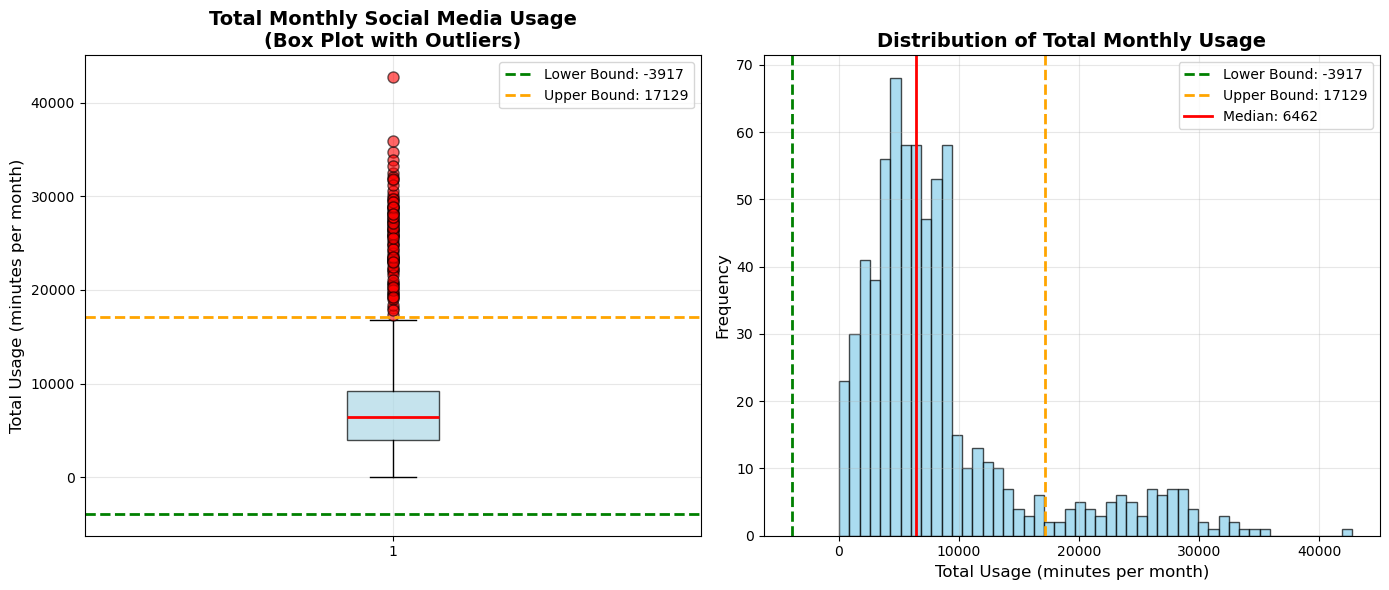


✓ Outlier analysis completed successfully!


In [14]:
print(f"\n{'='*70}")
print("OUTLIER COUNT SUMMARY")
print("="*70)
print(f"  Negative Outliers: {len(negative_outliers)} records ({len(negative_outliers)/len(df)*100:.2f}%)")
print(f"  Normal Range: {len(normal_range)} records ({len(normal_range)/len(df)*100:.2f}%)")
print(f"  Positive Outliers: {len(positive_outliers)} records ({len(positive_outliers)/len(df)*100:.2f}%)")

# # Show examples of outliers
# if len(negative_outliers) > 0:
#     print(f"\n⬇️  Examples of Negative Outliers (Low Usage):")
#     print(negative_outliers[['Age', 'Gender', 'Occupation', 'Total_Monthly_Usage']].head())

# if len(positive_outliers) > 0:
#     print(f"\n⬆️  Examples of Positive Outliers (High Usage):")
#     print(positive_outliers[['Age', 'Gender', 'Occupation', 'Total_Monthly_Usage']].head())

# Visualization
plt.figure(figsize=(14, 6))

# Box plot
plt.subplot(1, 2, 1)
box_plot = plt.boxplot(df['Total_Monthly_Usage'], patch_artist=True, vert=True,
                        boxprops=dict(facecolor='lightblue', alpha=0.7),
                        medianprops=dict(color='red', linewidth=2),
                        flierprops=dict(marker='o', markerfacecolor='red', 
                                      markersize=8, alpha=0.6))

plt.title('Total Monthly Social Media Usage\n(Box Plot with Outliers)', 
          fontsize=14, fontweight='bold')
plt.ylabel('Total Usage (minutes per month)', fontsize=12)
plt.grid(True, alpha=0.3)

# Add range annotations
plt.axhline(y=lower_bound, color='green', linestyle='--', linewidth=2, 
            label=f'Lower Bound: {lower_bound:.0f}')
plt.axhline(y=upper_bound, color='orange', linestyle='--', linewidth=2, 
            label=f'Upper Bound: {upper_bound:.0f}')
plt.legend(loc='upper right')

# Histogram
plt.subplot(1, 2, 2)
plt.hist(df['Total_Monthly_Usage'], bins=50, color='skyblue', alpha=0.7, edgecolor='black')
plt.axvline(x=lower_bound, color='green', linestyle='--', linewidth=2, 
            label=f'Lower Bound: {lower_bound:.0f}')
plt.axvline(x=upper_bound, color='orange', linestyle='--', linewidth=2, 
            label=f'Upper Bound: {upper_bound:.0f}')
plt.axvline(x=df['Total_Monthly_Usage'].median(), color='red', linestyle='-', 
            linewidth=2, label=f'Median: {df["Total_Monthly_Usage"].median():.0f}')

plt.title('Distribution of Total Monthly Usage', fontsize=14, fontweight='bold')
plt.xlabel('Total Usage (minutes per month)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Outlier analysis completed successfully!")

## 6. Categorical Feature Encoding

Machine learning algorithms require numerical input. We encode categorical features using appropriate techniques:

### Gender Encoding
- **Method**: Label Encoding
- **Rationale**: Gender is a binary categorical variable (Male/Female), making label encoding suitable
- **Encoding**: Male → 0, Female → 1

### Occupation Encoding
- **Method**: Label Encoding
- **Rationale**: For simplicity and to reduce dimensionality, we use label encoding. Alternatively, one-hot encoding could be used if treating occupation as non-ordinal is preferred
- **Impact**: Label encoding assumes ordinal relationship, which may not be ideal but works well for many clustering algorithms

In [15]:
# Encode categorical features
print("="*70)
print("CATEGORICAL FEATURE ENCODING")
print("="*70)

# Rename columns for clarity
df.rename(columns={
    'What is your age?': 'Age',
    'What is your current occupation?': 'Occupation'
}, inplace=True)

print("\n1. Gender Encoding (Label Encoding)")
print("-" * 70)
print(f"Original values: {df['Gender'].unique()}")

# Encode Gender
le_gender = LabelEncoder()
df['Gender_Encoded'] = le_gender.fit_transform(df['Gender'])

print(f"Encoded mapping:")
for i, label in enumerate(le_gender.classes_):
    print(f"  {label} → {i}")

print("\n2. Occupation Encoding (Label Encoding)")
print("-" * 70)
print(f"Original values: {df['Occupation'].unique()}")

# Encode Occupation
le_occupation = LabelEncoder()
df['Occupation_Encoded'] = le_occupation.fit_transform(df['Occupation'])

print(f"Encoded mapping:")
for i, label in enumerate(le_occupation.classes_):
    print(f"  {label} → {i}")

print("\n✓ Categorical encoding completed successfully!")
print("\nSample of encoded data:")
print(df[['Gender', 'Gender_Encoded', 'Occupation', 'Occupation_Encoded']].head())

CATEGORICAL FEATURE ENCODING

1. Gender Encoding (Label Encoding)
----------------------------------------------------------------------
Original values: ['Male' 'Female']
Encoded mapping:
  Female → 0
  Male → 1

2. Occupation Encoding (Label Encoding)
----------------------------------------------------------------------
Original values: ['Employed' 'Student' 'Unemployed' 'Businessperson' 'Worker' 'Driver']
Encoded mapping:
  Businessperson → 0
  Driver → 1
  Employed → 2
  Student → 3
  Unemployed → 4
  Worker → 5

✓ Categorical encoding completed successfully!

Sample of encoded data:
   Gender  Gender_Encoded Occupation  Occupation_Encoded
0    Male               1   Employed                   2
1  Female               0    Student                   3
2    Male               1    Student                   3
3    Male               1    Student                   3
4  Female               0    Student                   3


In [16]:
df.head()

,Gender,Age,Occupation,Facebook Week 1,Facebook Week 2,Facebook Week 3,Facebook Week 4,Messenger Week 1,Messenger Week 2,Messenger Week 3,...,TikTok Week 4,Facebook_Monthly_Total,Instagram_Monthly_Total,Messenger_Monthly_Total,TikTok_Monthly_Total,WhatsApp_Monthly_Total,YouTube_Monthly_Total,Total_Monthly_Usage,Gender_Encoded,Occupation_Encoded
0,Male,35,Employed,464.0,463.0,568.0,354.0,323.0,283.0,283.0,...,0.0,1849.0,1748.0,1186.0,0.0,1989.0,447.0,7219.0,1,2
1,Female,19,Student,51.0,52.0,74.0,59.0,51.0,53.0,55.0,...,0.0,236.0,92.0,210.0,0.0,275.0,63.0,876.0,0,3
2,Male,23,Student,13.0,24.0,44.0,1.0,2.0,10.0,1.0,...,0.0,82.0,0.0,52.0,0.0,83.0,106.0,323.0,1,3
3,Male,21,Student,1457.0,1282.0,1538.0,1391.0,249.0,278.0,220.0,...,0.0,5668.0,351.0,1050.0,0.0,248.0,792.0,8109.0,1,3
4,Female,19,Student,326.0,277.0,367.0,305.0,274.0,222.0,203.0,...,0.0,1275.0,1046.0,896.0,0.0,543.0,1112.0,4872.0,0,3


## 8. Export Cleaned Dataset

### Prepare Final Dataset

We prepare two versions of the cleaned dataset:

1. **Unscaled Version**: Contains original values with encodings (for interpretability)
2. **Scaled Version**: Contains standardized features (ready for K-Means clustering)

Both datasets include:
- Original demographic information
- Encoded categorical features
- Weekly usage data (converted to minutes)
- Monthly usage totals
- Properly cleaned and validated records

In [17]:
# Calculate Total Monthly Social Media Usage (all platforms combined)
print("="*70)
print("REMOVING OUTLIERS FROM DATASET")
print("="*70)

# Calculate IQR bounds
Q1 = df['Total_Monthly_Usage'].quantile(0.25)
Q3 = df['Total_Monthly_Usage'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"IQR Analysis:")
print(f"  Q1 (25th percentile): {Q1:.2f} minutes")
print(f"  Q3 (75th percentile): {Q3:.2f} minutes")
print(f"  IQR (Q3 - Q1): {IQR:.2f} minutes")
print(f"  Lower Bound: {lower_bound:.2f} minutes")
print(f"  Upper Bound: {upper_bound:.2f} minutes")

# Filter the dataset to remove outliers
df_no_outliers = df[(df['Total_Monthly_Usage'] >= lower_bound) & (df['Total_Monthly_Usage'] <= upper_bound)]
outliers = df[(df['Total_Monthly_Usage'] < lower_bound) | (df['Total_Monthly_Usage'] > upper_bound)]

print(f"\nOriginal Dataset Shape: {df.shape}")
print(f"New Dataset Shape (No Outliers): {df_no_outliers.shape}")

# Save the new dataset without outliers to a CSV file
output_path_no_outliers = 'Social_Media_Addiction_No_Outliers.csv'
df_no_outliers.to_csv(output_path_no_outliers, index=False)
print(f"✓ Dataset without outliers saved: {output_path_no_outliers}")



REMOVING OUTLIERS FROM DATASET
IQR Analysis:
  Q1 (25th percentile): 3975.50 minutes
  Q3 (75th percentile): 9237.00 minutes
  IQR (Q3 - Q1): 5261.50 minutes
  Lower Bound: -3916.75 minutes
  Upper Bound: 17129.25 minutes

Original Dataset Shape: (691, 36)
New Dataset Shape (No Outliers): (609, 36)
✓ Dataset without outliers saved: Social_Media_Addiction_No_Outliers.csv


In [18]:
print(f"Outlier Dataset Shape: {outliers.shape}")

# Save the outlier dataset to a CSV file
output_path_outliers = 'Social_Media_Addiction_Outliers.csv'
outliers.to_csv(output_path_outliers, index=False)
print(f"✓ Outlier dataset saved: {output_path_outliers}")

Outlier Dataset Shape: (82, 36)
✓ Outlier dataset saved: Social_Media_Addiction_Outliers.csv


### Final Dataset Preview

Display a preview of the cleaned dataset to verify the preprocessing results.

In [19]:
# Display final dataset preview
print("="*70)
print("FINAL CLEANED DATASET PREVIEW")
print("="*70)

print("\nUnscaled Dataset (First 10 rows):")

df_no_outliers.head(10)

print("\n" + "="*70)
print("STATISTICAL SUMMARY")
print("="*70)
print(df_no_outliers.describe())

print("\n" + "="*70)
print("DATA TYPES")
print("="*70)
print(df_no_outliers.dtypes)

print("\n" + "="*70)
print("DATASET INFO")
print("="*70)
print(f"Shape: {df_no_outliers.shape}")
print(f"Memory Usage: {df_no_outliers.memory_usage(deep=True).sum() / 1024:.2f} KB")

FINAL CLEANED DATASET PREVIEW

Unscaled Dataset (First 10 rows):

STATISTICAL SUMMARY
              Age  Facebook Week 1  Facebook Week 2  Facebook Week 3  \
count  609.000000       609.000000       609.000000       609.000000   
mean    25.210181       409.786535       409.302135       419.341544   
std      6.677621       495.552905       503.938323       518.423025   
min     16.000000         0.000000         0.000000         0.000000   
25%     21.000000       112.000000       100.000000        96.000000   
50%     23.000000       233.000000       229.000000       232.000000   
75%     26.000000       421.000000       443.000000       438.000000   
max     50.000000      2967.000000      3069.000000      2895.000000   

       Facebook Week 4  Messenger Week 1  Messenger Week 2  Messenger Week 3  \
count       609.000000        609.000000        609.000000        609.000000   
mean        417.937603        246.592775        248.211823        248.755337   
std         516.431368   